# SVM Sentiment Analysis — Amazon Reviews

Analiza sentymentu recenzji Amazon za pomocą SVM z pełnym pipeline'em:
- **TF-IDF** jako reprezentacja tekstu (z n-gramami)
- **LinearSVC** jako klasyfikator (zoptymalizowany pod kątem dużych zbiorów danych)
- **Podział danych**: Prosty podział Train (80%) / Test (20%)
- **Model Tuning**: GridSearchCV z wykorzystaniem 5-fold Cross-Validation na zbiorze treningowym
- **Finalna ewaluacja**: Sprawdzenie modelu na odłożonym zbiorze testowym

```
Cały dataset (ok. 90k próbek)
│
├── Zbiór Treningowy (80%)  ← Tu szukamy parametrów (GridSearch + CV)
│                              i trenujemy finalny model.
│
└── Zbiór Testowy (20%)     ← Finalny sprawdzian (tylko raz na końcu)
```

**Strategia walidacji:**
Przy 90k próbek rezygnujemy z wydzielania osobnego, statycznego zbioru walidacyjnego na rzecz **Cross-Validation** wewnątrz procedury GridSearch. Pozwala to na bardziej stabilną ocenę parametrów przy jednoczesnym zachowaniu większej ilości danych do samej nauki modelu.

**Uwaga o zbiorze danych:**
Plik `processed_reviews.csv` zawiera zbalansowany zbiór klas (po tyle samo przykładów negatywnych, neutralnych i pozytywnych). Wyniki należy więc interpretować jako jakość modelu na zbiorze zrównoważonym, a nie bezpośrednio na naturalnym rozkładzie ocen w oryginalnych recenzjach Amazon.

## 1. Importy

In [1]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

print("Importy zaladowane pomyslnie.")

Importy zaladowane pomyslnie.


## 2. Wczytanie danych

In [2]:
df = pd.read_csv('data/processed_reviews.csv')

print(f"Liczba probek: {len(df)}")
print(f"Kolumny: {df.columns.tolist()}")
print("\nRozklad klas (label):")
print(df['label'].value_counts().sort_index())

df.head(3)

Liczba probek: 89511
Kolumny: ['id', 'full_text', 'score', 'sentiment', 'label']

Rozklad klas (label):
label
0    29837
1    29837
2    29837
Name: count, dtype: int64


,id,full_text,score,sentiment,label
0,497575,It's not equal amounts of each flavor... Just ...,3,0,1
1,333710,Not A Gingerbread Man These do taste very good...,4,1,2
2,275773,"great taste great taste, good price... Always ...",5,1,2


## 3. Podział danych: Train / Test

Wykorzystujemy 80% danych do treningu i 20% do testu. Stratyfikacja (`stratify=y`) zapewnia, że rozkład klas (Negative / Neutral / Positive) w obu zbiorach będzie identyczny jak w przetworzonym, zbalansowanym pliku. 

Zbiór testowy zostaje odłożony i nie bierze udziału w procesie uczenia ani doboru parametrów.

In [3]:
X = df['full_text']
y = df['label']

# Podział danych: 80% treningowy, 20% testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y  # Zachowuje proporcje klas w obu zbiorach
)

# Wyświetlenie statystyk
print(f"Train: {len(X_train):>6} próbek ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test:  {len(X_test):>6} próbek ({len(X_test)/len(X)*100:.1f}%)")

print("\nRozkład klas w Train:")
print(y_train.value_counts().sort_index())

print("\nRozkład klas w Test:")
print(y_test.value_counts().sort_index())

Train:  71608 próbek (80.0%)
Test:   17903 próbek (20.0%)

Rozkład klas w Train:
label
0    23870
1    23869
2    23869
Name: count, dtype: int64

Rozkład klas w Test:
label
0    5967
1    5968
2    5968
Name: count, dtype: int64


## 4. Baseline Pipeline

Bazowy pipeline z parametrami wynikającymi z wcześniejszych eksperymentów.

Kluczowe decyzje projektowe:
- `stop_words=None` — negacje ('not', 'no') niosą istotną informację o sentymencie
- `ngram_range=(1,3)` — trigramy łapią frazy jak 'not good at all'
- `min_df=3` — odcina rzadkie cechy, redukuje szum
- `class_weight=None` — klasy są już zbalansowane w danych, wyrównywanie wag byłoby zbędne
- Pipeline gwarantuje brak data leakage — TF-IDF fitowany osobno w każdym foldzie CV

In [4]:
baseline_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        stop_words=None,
        token_pattern=r'(?u)\b\w\w+\b',
        ngram_range=(1, 3),
        lowercase=True,
        min_df=3
    )),
    ('svm', LinearSVC(
        C=1,
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

print("Pipeline zdefiniowany:")
print(baseline_pipe)

Pipeline zdefiniowany:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=30000, min_df=3,
                                 ngram_range=(1, 3))),
                ('svm', LinearSVC(C=1, max_iter=3000, random_state=42))])


## 5. Baseline Cross-Validation

5-fold CV na `X_train` — punkt odniesienia przed GridSearch.
Sprawdzamy czy parametry z wcześniejszych eksperymentów są dobrym punktem startowym
i czy model jest stabilny (mała wariancja między foldami).

Uruchamianie 5-fold CV (baseline)...
Czas: 38.2s

Baseline CV F1-macro: 0.7473 +/- 0.0018
Wyniki per fold:      [0.7474 0.7465 0.746  0.7507 0.746 ]


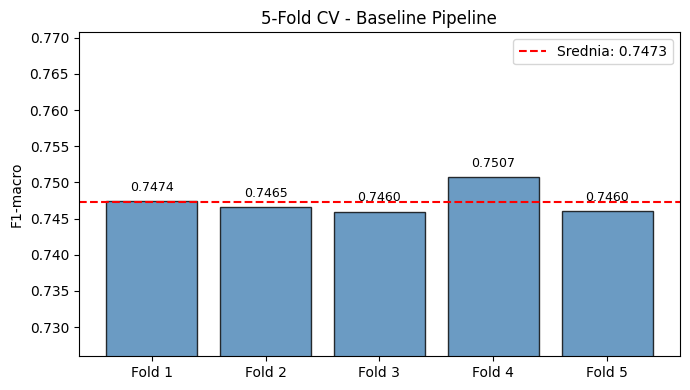

In [5]:
print("Uruchamianie 5-fold CV (baseline)...")
start = time.time()

cv_scores = cross_val_score(
    baseline_pipe,
    X_train, y_train,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

print(f"Czas: {time.time() - start:.1f}s")
print(f"\nBaseline CV F1-macro: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"Wyniki per fold:      {np.round(cv_scores, 4)}")

fig, ax = plt.subplots(figsize=(7, 4))
folds = [f'Fold {i+1}' for i in range(len(cv_scores))]
bars = ax.bar(folds, cv_scores, color='steelblue', alpha=0.8, edgecolor='black')
ax.axhline(cv_scores.mean(), color='red', linestyle='--',
           label=f'Srednia: {cv_scores.mean():.4f}')
ax.set_ylim(max(0, cv_scores.min() - 0.02), min(1, cv_scores.max() + 0.02))
ax.set_ylabel('F1-macro')
ax.set_title('5-Fold CV - Baseline Pipeline')
ax.legend()
for bar, score in zip(bars, cv_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{score:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 6. GridSearchCV — dobór hiperparametrów

GridSearchCV przeszukuje siatkę parametrów, wykonując **5-fold Cross-Validation** na zbiorze treningowym. Oznacza to, że dla każdej kombinacji parametrów model trenuje się 5 razy na różnych częściach zbioru `X_train`.

Siatka testuje:
- `max_features` / `ngram_range` — jak bogaty ma być słownik TF-IDF.
- `svm__C` — siłę regularyzacji LinearSVC (kluczowy parametr dla stabilności modelu).

Po znalezieniu najlepszej kombinacji, dzięki `refit=True`, model zostaje automatycznie wytrenowany na **całym 80-procentowym zbiorze treningowym**.

In [6]:
gs_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        stop_words=None,
        token_pattern=r'(?u)\b\w\w+\b',
        min_df=3
    )),
    ('svm', LinearSVC(
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

# 3 x 2 x 3 = 18 kombinacji x 5 foldow = 90 fitow
# class_weight pomijamy — klasy sa zbalansowane w pliku processed_reviews.csv
param_grid = {
    'tfidf__max_features': [15000, 30000, None],
    'tfidf__ngram_range':  [(1, 2), (1, 3)],
    'svm__C':              [0.3, 1, 5],
}

grid_search = GridSearchCV(
    gs_pipe,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Liczba kombinacji: 18 x 5 foldow = 90 fitow")
print("Uruchamianie GridSearchCV...")
start = time.time()

grid_search.fit(X_train, y_train)

print(f"\nGotowe! Czas: {time.time() - start:.1f}s")
print(f"\nNajlepsze parametry:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nNajlepszy CV F1-macro (train): {grid_search.best_score_:.4f}")

Liczba kombinacji: 18 x 5 foldow = 90 fitow
Uruchamianie GridSearchCV...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Gotowe! Czas: 476.6s

Najlepsze parametry:
  svm__C: 0.3
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)

Najlepszy CV F1-macro (train): 0.7676


In [7]:
# Top 10 kombinacji
# Mala roznica miedzy top1 a top10 = model stabilny, nie ma jednej magicznej kombinacji
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = (cv_results
         .sort_values('mean_test_score', ascending=False)
         .head(10)[['param_tfidf__max_features', 'param_tfidf__ngram_range',
                    'param_svm__C',
                    'mean_test_score', 'std_test_score']]
         .reset_index(drop=True))

top10.columns = ['max_features', 'ngram_range', 'C', 'mean_F1', 'std_F1']
top10['mean_F1'] = top10['mean_F1'].round(4)
top10['std_F1']  = top10['std_F1'].round(4)

print("Top 10 kombinacji hiperparametrow:")
display(top10)

Top 10 kombinacji hiperparametrow:


,max_features,ngram_range,C,mean_F1,std_F1
0,None,"(1, 3)",0.3,0.7676,0.0033
1,None,"(1, 2)",0.3,0.7653,0.0037
2,None,"(1, 3)",1.0,0.7629,0.0022
3,30000,"(1, 3)",0.3,0.7628,0.0020
4,30000,"(1, 2)",0.3,0.7608,0.0024
5,15000,"(1, 3)",0.3,0.7608,0.0024
6,15000,"(1, 2)",0.3,0.7588,0.0018
7,None,"(1, 2)",1.0,0.7579,0.0037
8,None,"(1, 3)",5.0,0.7527,0.0019
9,30000,"(1, 3)",1.0,0.7473,0.0018


## 7. Finalna ewaluacja na zbiorze testowym

To najważniejszy punkt eksperymentu. Uruchamiamy najlepszy model na danych testowych (20%), których model nigdy wcześniej nie widział. Wynik ten jest ostateczną miarą zdolności modelu do generalizacji na nowe opinie klientów.

In [8]:

best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test)
test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("=" * 55)
print("FINALNE WYNIKI NA ZBIORZE TESTOWYM")
print("=" * 55)
print(f"CV F1-macro  (GridSearch, train): {grid_search.best_score_:.4f}")
print(f"F1-macro     (test):              {test_f1:.4f}")
print()
print(classification_report(
    y_test, y_test_pred,
    target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']
))

FINALNE WYNIKI NA ZBIORZE TESTOWYM
CV F1-macro  (GridSearch, train): 0.7676
F1-macro     (test):              0.7768

                precision    recall  f1-score   support

Negative (1-2)       0.78      0.78      0.78      5967
   Neutral (3)       0.70      0.69      0.70      5968
Positive (4-5)       0.85      0.87      0.86      5968

      accuracy                           0.78     17903
     macro avg       0.78      0.78      0.78     17903
  weighted avg       0.78      0.78      0.78     17903



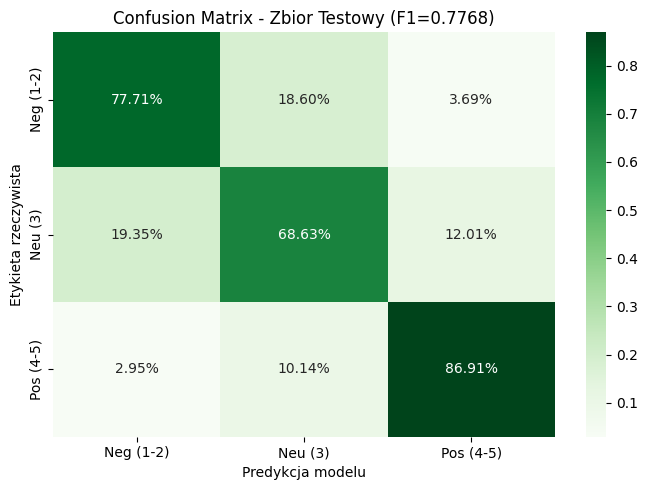

In [9]:
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()

## 8. Interpretacja wyników

Finalny wynik testowy (`F1-macro = 0.7768`) jest nieco wyższy niż średni wynik walidacji krzyżowej z GridSearchCV (`0.7676`), co nie wskazuje na przeuczenie modelu na zbiorze treningowym. Najlepszy model uzyskał najwyższy wynik dla `max_features=None`, `ngram_range=(1, 3)` oraz `C=0.3`, co sugeruje, że bogatsza reprezentacja tekstu połączona z silniejszą regularyzacją działa korzystnie dla tego zbioru.

Najtrudniejszą klasą pozostaje `Neutral (3)` (`F1 = 0.70`). Jest to oczekiwane w analizie sentymentu, ponieważ recenzje neutralne często zawierają zarówno elementy pozytywne, jak i negatywne, przez co granica decyzyjna między klasami jest mniej jednoznaczna. Wariant `max_features=None` daje najlepszy wynik, ale zwiększa rozmiar słownika TF-IDF i koszt pamięciowy modelu.

## 9. Podsumowanie

In [10]:
print("=" * 55)
print("PODSUMOWANIE EKSPERYMENTU")
print("=" * 55)
print(f"\nPodzial danych:")
print(f"  Train:      {len(X_train):>6} probek ({len(X_train)/len(X)*100:.1f}%)")
print(f"  Test:       {len(X_test):>6} probek ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nWyniki:")
print(f"  Baseline CV F1-macro (5-fold): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"  GridSearch CV F1-macro:        {grid_search.best_score_:.4f}")
print(f"  Test F1-macro (FINALNA):       {test_f1:.4f}")
print(f"\nNajlepsze hiperparametry:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")

PODSUMOWANIE EKSPERYMENTU

Podzial danych:
  Train:       71608 probek (80.0%)
  Test:        17903 probek (20.0%)

Wyniki:
  Baseline CV F1-macro (5-fold): 0.7473 +/- 0.0018
  GridSearch CV F1-macro:        0.7676
  Test F1-macro (FINALNA):       0.7768

Najlepsze hiperparametry:
  svm__C: 0.3
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)


## 10. Analiza błędów

In [11]:
results_df = pd.DataFrame({
    'text':      X_test.values,
    'actual':    y_test.values,
    'predicted': y_test_pred
})

errors = results_df[results_df['actual'] != results_df['predicted']]
print(f"Blednych predykcji: {len(errors)} / {len(results_df)} "
      f"({len(errors)/len(results_df)*100:.1f}%)")

label_values = sorted(y.unique())
neg_label = label_values[0]
pos_label = label_values[-1]

extreme = errors[(errors['actual'] == neg_label) & (errors['predicted'] == pos_label)]
print(f"\nSkrajne pomylki (Negatyw -> Pozytyw): {len(extreme)}")

for _, row in extreme.head(5).iterrows():
    print(f"\n[actual={row['actual']} | pred={row['predicted']}]")
    print(f"  {str(row['text'])[:250]}...")

Blednych predykcji: 3983 / 17903 (22.2%)

Skrajne pomylki (Negatyw -> Pozytyw): 220

[actual=0 | pred=2]
  Serious health food If you're out for sheer health benefits without taste and without desirable texture, this one's for you.  I did not expect much out of it except health benefits, so I wasn't surprised.  You should only try this product if you have...

[actual=0 | pred=2]
  My cat hates this stuff... I had to but my cat friskee pate canned cat food instead of this canned stuff. My cat lost weight cause she wouldnt eat it. I had 2 different cases from amazon and also different flavors of filet that i had brought from the...

[actual=0 | pred=2]
  I was hoping to love this coffee, but it is very bitter. I have been searching for a smooth, flavorful decaf K cup that I could actually enjoy. I was thrilled to find  Folgers Gourmet Lively Columbian medium roast decaf K cup to try, but both my husb...

[actual=0 | pred=2]
  frenchs horseradish mustard first of all I like Frenchs regula